# A catalyst series: an enantioselectivity as the activity

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/09_a_catalyst_series.ipynb)

The earlier notebooks model a binding constant, an adsorption energy and a substituent constant.
This one models a property of **kinetics**: how selective a catalyst is. The method applies to
it for the same reason. A selectivity is a ratio of two rate constants, and its logarithm is a
difference of two free energies, as the logarithm of a binding constant is.

The series is the screen of Zahrt, Henle, Rose, Wang, Darrow and Denmark (Science 2019, 363,
eaau5631): 43 chiral phosphoric acids, each used as the catalyst of 25 reactions, the additions
of 5 thiols to 5 imines. Every reaction gives two mirror-image products, and the measured number
is the **enantiomeric excess** (ee), the excess of one product over the other. The activity is

ΔΔG‡ = R T ln((1 + ee) / (1 − ee)),

the difference in free energy between the two transition states that lead to the two products,
in kcal/mol. A catalyst with no selectivity has ΔΔG‡ = 0, and 90 % ee is 1.74 kcal/mol.

Two things make the series a good lesson.

- **The frame is the reaction centre.** Every catalyst is the same phosphoric acid on a
  binaphthyl scaffold, with one substituent at each of the two positions next to the acid. So
  the acid group is put in the same place for all catalysts by a rule, and the substituents then
  lie around the pocket where the reaction takes place. Nothing is aligned by a fit.
- **What the frame is worth can be measured.** The same fields can be compared without any frame,
  through the rotation-invariant kernel of the second notebook. On a series of ligands the
  alignment is itself uncertain, so that comparison is never clean. Here it is.

The files are in `examples/denmark`. They were built from the supplementary data of the paper;
`examples/denmark/README.md` gives the source and its status.

Running time: about two minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data: 43 catalysts, 25 reactions each

`load_dataset` reads the catalysts. Every catalyst is stored as two records with one name, and
`ensemble_by="name"` joins them into one molecule with two conformations. The reason for the two
records is given below. The table of the reactions gives one ΔΔG‡ for every catalyst and every
pair of an imine (1 to 5) and a thiol (A to E).

In [2]:
import csv
import numpy as np
import matplotlib.pyplot as plt
from cmfqsar import load_dataset

ds = load_dataset("examples/denmark/catalysts_sym.sdf", ensemble_by="name")
mols, names = ds.mols, ds.names
with open("examples/denmark/reactions.csv", encoding="utf-8", newline="") as fh:
    reactions = list(csv.DictReader(fh))
pairs = sorted({(r["thiol"], r["imine"]) for r in reactions})          # the 25 substrate pairs
ddG = np.full((len(names), len(pairs)), np.nan)
for r in reactions:
    ddG[names.index(r["catalyst"]), pairs.index((r["thiol"], r["imine"]))] = float(r["ddG_kcal"])

print(len(names), "catalysts,", mols[0].GetNumConformers(), "conformations each;", len(reactions), "reactions")
ee = 0.90
print("90 %% ee is %.2f kcal/mol" % (1.98720e-3 * 298.15 * np.log((1 + ee) / (1 - ee))))
print("ddG runs from %+.2f to %+.2f kcal/mol, standard deviation %.2f" % (ddG.min(), ddG.max(), ddG.std()))

43 catalysts, 2 conformations each; 1075 reactions
90 % ee is 1.74 kcal/mol
ddG runs from -0.42 to +3.14 kcal/mol, standard deviation 0.70


The picture below shows the whole table: one row for every catalyst, sorted by its mean, and one
column for every pair of substrates, grouped by the thiol.

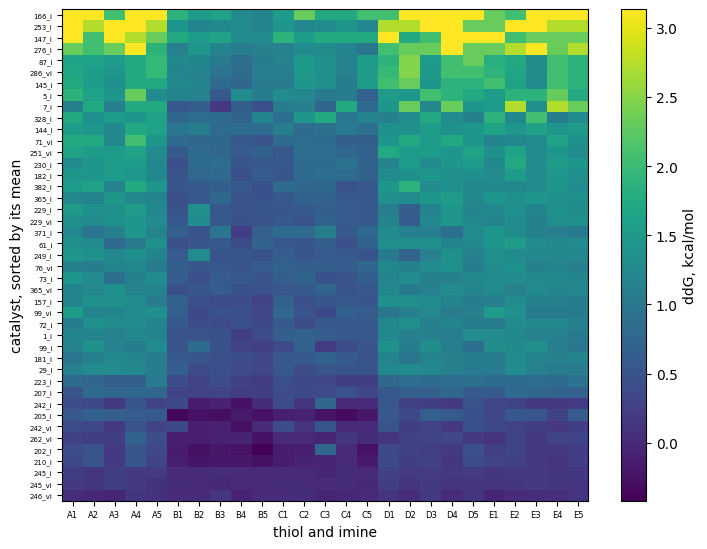

share of the variance of the 1075 values that the mean of the catalyst holds: 0.68
share that the mean of the catalyst plus an offset of the substrate pair holds: 0.89
mean of a thiol over all its reactions: A 1.25  B 0.54  C 0.67  D 1.24  E 1.24


In [3]:
mean_ddG = ddG.mean(axis=1)
order = np.argsort(mean_ddG)
fig, ax = plt.subplots(figsize=(7.4, 5.6))
image = ax.imshow(ddG[order], aspect="auto", cmap="viridis", origin="lower")
ax.set_xticks(range(len(pairs))); ax.set_xticklabels([t + i for t, i in pairs], fontsize=6)
ax.set_yticks(range(len(names))); ax.set_yticklabels([names[k] for k in order], fontsize=5)
ax.set_xlabel("thiol and imine"); ax.set_ylabel("catalyst, sorted by its mean")
fig.colorbar(image, label="ddG, kcal/mol"); plt.tight_layout(); plt.show()

total = np.sum((ddG - ddG.mean()) ** 2)
by_catalyst = 1 - np.sum((ddG - ddG.mean(axis=1, keepdims=True)) ** 2) / total
additive = ddG.mean(axis=1, keepdims=True) + ddG.mean(axis=0) - ddG.mean()
print("share of the variance of the 1075 values that the mean of the catalyst holds: %.2f" % by_catalyst)
print("share that the mean of the catalyst plus an offset of the substrate pair holds: %.2f" % (1 - np.sum((ddG - additive) ** 2) / total))
print("mean of a thiol over all its reactions:", "  ".join("%s %.2f" % (t, ddG[:, [p[0] == t for p in pairs]].mean()) for t in "ABCDE"))

The rows differ much more than the columns. The mean of a catalyst over its 25 reactions holds
two thirds of all the variance, and with one offset for every pair of substrates the share is
0.89. So a selective catalyst is selective for all 25 reactions, and the substrates add a shift:
the two aliphatic thiols (B and C) give lower values than the three aromatic ones.

The activity of this notebook is therefore **the mean ΔΔG‡ of a catalyst**, one number for each
of the 43. The last section goes back from this number to the single reactions.

## Look at the structures before the model

A model cannot be better than its structures, and a score does not show a faulty one. The check
costs a second: every bond length must be near the sum of the covalent radii of its two atoms,
and two atoms without a bond must not be close.

In [4]:
from cmfqsar.orca import changed_bonds

faults = []
for m, name in zip(mols, names):
    for image in range(m.GetNumConformers()):
        xyz = np.array(m.GetConformer(image).GetPositions())
        distance = np.linalg.norm(xyz[:, None, :] - xyz[None, :, :], axis=2)
        np.fill_diagonal(distance, np.inf)
        for bond in m.GetBonds():
            i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
            distance[i, j] = distance[j, i] = np.inf
        if distance.min() < 1.3:
            faults.append((name, "two atoms without a bond %.2f A apart" % distance.min()))
    faults += [(name, fault) for fault in changed_bonds(m, low=0.7, high=1.3)]
print("structures with a fault:", faults if faults else "none")

structures with a fault: none


This check is here for a reason. Until 14 November 2026 the file held one faulty structure: the
catalyst `181_i`, which has two SF<sub>5</sub> groups. No force field of the toolkit that built
the structures has this group, and the one that was used moved the fluorine atoms 6 to 8 Å away
from the sulfur. The score of the model with all fields was the same with that structure. One
comparison of this notebook was not: without a frame the model looked much worse than it is. The
check above finds that structure at once.

## The frame

The phosphorus is at the origin. The two oxygens of the acid that take part in the reaction point
to +z, so the pocket in which the imine and the thiol meet is above the phosphorus. The two
substituents lie to the left and to the right of it, along x. The plot shows the heavy atoms of
all 43 catalysts in this frame.

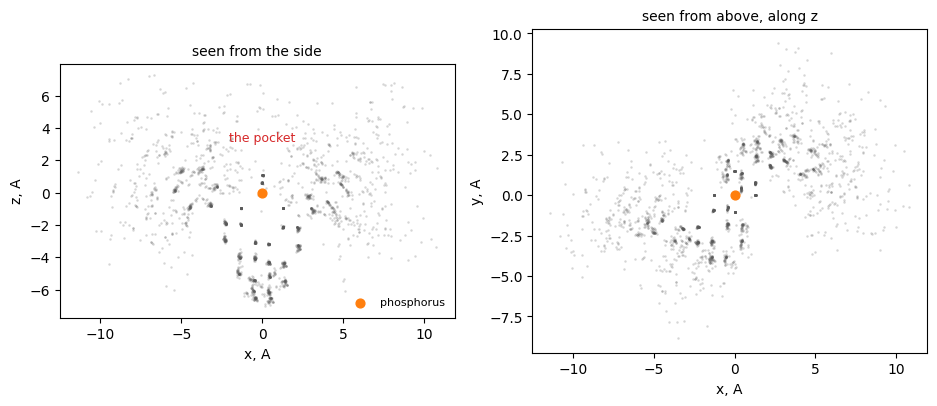

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2))
for m in mols:
    xyz = np.array(m.GetConformer(0).GetPositions())
    heavy = np.array([a.GetAtomicNum() > 1 for a in m.GetAtoms()])
    axes[0].scatter(xyz[heavy, 0], xyz[heavy, 2], s=3, color="0.35", alpha=0.25, lw=0)
    axes[1].scatter(xyz[heavy, 0], xyz[heavy, 1], s=3, color="0.35", alpha=0.25, lw=0)
for ax, vertical, title in ((axes[0], "z", "seen from the side"), (axes[1], "y", "seen from above, along z")):
    ax.scatter([0], [0], s=40, color="tab:orange", zorder=3, label="phosphorus")
    ax.set_xlabel("x, A"); ax.set_ylabel(vertical + ", A"); ax.set_aspect("equal"); ax.set_title(title, fontsize=10)
axes[0].annotate("the pocket", (0, 3.2), ha="center", fontsize=9, color="tab:red")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

The scaffold is the dense part below the phosphorus. The two wide clouds at the sides are the
substituents, which is where the 43 catalysts differ.

The catalyst has a twofold axis of symmetry along z. A rotation by 180° about z gives the same
molecule with its two halves exchanged, and nothing says which half belongs on +x. So the file
holds both images of every catalyst, and the option `conformers="ensemble"` averages the fields
of the two. The field of a catalyst then has the symmetry of the catalyst.

## The model, and how it is validated

The model is the kernel ridge regression of the other notebooks on the overlap kernel of the
five fields. With 43 catalysts every one of them counts, so the validation is **leave one
catalyst out**: each catalyst is predicted by a model fitted to the other 42. The attenuation of
the fields and the ridge parameter are chosen inside those 42, again by leaving one out, so the
catalyst that is predicted takes no part in the choice.

The next cell holds this as a few short functions. They take kernel matrices, so the same
functions serve every description below.

In [6]:
from collections import Counter
from cmfqsar import CMFModel
from cmfqsar.fields import AtomTable, FieldSet, build_fields
from cmfqsar.model import krr_fit

FIVE = ["electrostatic", "steric", "hydrophobic", "hba", "hbd"]
ALPHAS = [0.3, 0.5, 0.8, 1.2, 2.0, 3.0]            # the attenuation of the fields
RIDGES = [1e-3, 1e-2, 0.1, 1.0, 10.0]
y = mean_ddG


def field_table(fields, alpha):
    fieldset = FieldSet.create(physchem=list(fields), alpha=alpha, conformers="ensemble")
    return fieldset, AtomTable.from_molecules([build_fields(m, fieldset, name=n) for m, n in zip(mols, names)])


# The kernel of several fields is the sum of the kernels of the single fields, each scaled so
# that its mean diagonal is 1. So the kernels are computed once for every attenuation, field by
# field, and the kernel of any set of fields is a sum of these blocks.
BLOCKS = {}
for alpha in ALPHAS:
    fieldset, table = field_table(FIVE, alpha)
    model = CMFModel(fieldset=fieldset, method="krr")
    per_field = model.prepare_training_kernels(table)           # one matrix for every field
    BLOCKS[alpha] = model.scale[:, None, None] * per_field


def overlap_kernels(fields):
    """The kernel of the catalysts in the frame for these fields, one matrix per attenuation."""
    rows = [FIVE.index(f) for f in fields]
    return {alpha: blocks[rows].sum(axis=0) for alpha, blocks in BLOCKS.items()}


def leave_one_out(K, y, ridge):
    """The prediction of every sample by a kernel ridge model fitted without it. A ridge model
    is linear in y, predicted = S y, and for such a model the error without sample i is
    (y_i - predicted_i) / (1 - S_ii), so one matrix inverse gives all of them."""
    n = len(y)
    A = np.zeros((n + 1, n + 1))                      # the equations of krr_fit, with the bias
    A[:n, :n] = K + ridge * np.eye(n)
    A[:n, n] = A[n, :n] = 1.0
    inverse = np.linalg.inv(A)
    S = K @ inverse[:n, :n] + inverse[n, :n][None, :]
    return y - (y - S @ y) / (1.0 - np.diag(S))


def cross_validate(kernels, y):
    """Every catalyst predicted without itself. The kernel setting and the ridge parameter are
    chosen by leave-one-out inside the other 42. Returns the predictions and the choices."""
    predicted, chosen = np.empty(len(y)), Counter()
    for i in range(len(y)):
        train = np.delete(np.arange(len(y)), i)
        best = None
        for setting, K in kernels.items():
            for ridge in RIDGES:
                error = np.sum((y[train] - leave_one_out(K[np.ix_(train, train)], y[train], ridge)) ** 2)
                if best is None or error < best[0]:
                    best = (error, setting, ridge)
        _, setting, ridge = best
        coefficients, bias = krr_fit(kernels[setting][np.ix_(train, train)], y[train], ridge)
        predicted[i] = kernels[setting][i, train] @ coefficients + bias
        chosen[setting, ridge] += 1
    return predicted, chosen


def q2(y, predicted):
    return 1.0 - np.sum((y - predicted) ** 2) / np.sum((y - np.mean(y)) ** 2)


def difference(y, a, b, runs=5000, seed=0):
    """q2 of the predictions `a` minus q2 of the predictions `b`, with a 95 % interval from a
    bootstrap over the catalysts."""
    error_a, error_b = (a - y) ** 2, (b - y) ** 2
    rng, draws = np.random.RandomState(seed), []
    for _ in range(runs):
        rows = rng.randint(0, len(y), len(y))
        draws.append((error_b[rows].sum() - error_a[rows].sum()) / np.sum((y[rows] - y[rows].mean()) ** 2))
    value = (error_b.sum() - error_a.sum()) / np.sum((y - y.mean()) ** 2)
    return "%+.2f [%+.2f, %+.2f]" % (value, np.percentile(draws, 2.5), np.percentile(draws, 97.5))

closed form of leave-one-out against 43 separate fits: largest difference 4e-13


five fields: q2 0.88, mean absolute error 0.16 kcal/mol
chosen in 37 of 43 folds: attenuation 0.8, ridge parameter 0.1


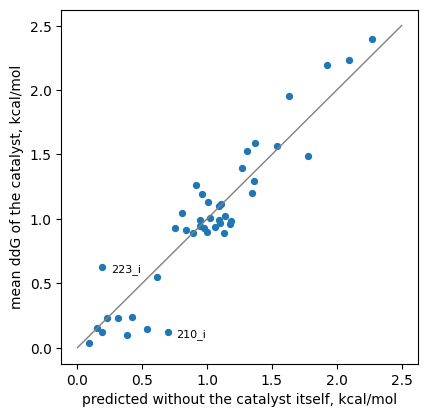

In [7]:
K = overlap_kernels(FIVE)[0.8]
explicit = np.empty(len(y))
for i in range(len(y)):                               # the same without the closed form
    train = np.delete(np.arange(len(y)), i)
    coefficients, bias = krr_fit(K[np.ix_(train, train)], y[train], 0.1)
    explicit[i] = K[i, train] @ coefficients + bias
print("closed form of leave-one-out against 43 separate fits: largest difference %.0e" % np.abs(explicit - leave_one_out(K, y, 0.1)).max())

predictions = {}
predictions["five fields"], chosen = cross_validate(overlap_kernels(FIVE), y)
(alpha, ridge), times = chosen.most_common(1)[0]
print("five fields: q2 %.2f, mean absolute error %.2f kcal/mol" % (q2(y, predictions["five fields"]), np.mean(np.abs(y - predictions["five fields"]))))
print("chosen in %d of %d folds: attenuation %g, ridge parameter %g" % (times, len(y), alpha, ridge))

p = predictions["five fields"]
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.scatter(p, y, s=18, color="tab:blue")
ax.plot([0, 2.5], [0, 2.5], color="0.5", lw=1)
for k in np.argsort(-np.abs(y - p))[:2]:
    ax.annotate(names[k], (p[k], y[k]), textcoords="offset points", xytext=(6, -3), fontsize=8)
ax.set_xlabel("predicted without the catalyst itself, kcal/mol"); ax.set_ylabel("mean ddG of the catalyst, kcal/mol")
plt.show()

The model explains almost nine tenths of the variance of a catalyst that it has not seen, with a
mean error of 0.16 kcal/mol on a scale that runs from 0 to 2.4.

The two catalysts with the largest errors are named in the plot, and they have one thing in
common. In `210_i` a CH<sub>2</sub> group lies between the scaffold and the aryl group, and in
`223_i` a silicon atom. The group can turn about that link, so where it lies is a choice between
conformations, and the file holds one conformation for each catalyst. A model in a frame is as
good as the conformations it is given.

## Which field carries the selectivity

The same validation with one field at a time.

In [8]:
for field in FIVE:
    predictions[field], _ = cross_validate(overlap_kernels([field]), y)
print("%-16s %6s %22s" % ("", "q2", "mean absolute error"))
for label in ["five fields"] + FIVE:
    print("%-16s %6.2f %22.2f" % (label, q2(y, predictions[label]), np.mean(np.abs(y - predictions[label]))))
print()
print("five fields minus the steric field alone:", difference(y, predictions["five fields"], predictions["steric"]))

                     q2    mean absolute error
five fields        0.88                   0.16
electrostatic      0.50                   0.33
steric             0.80                   0.20
hydrophobic        0.70                   0.23
hba                0.35                   0.35
hbd                0.01                   0.45



five fields minus the steric field alone: +0.08 [+0.01, +0.18]


The steric field alone reaches 0.80, and the hydrophobic field, which also grows with the amount
of carbon, 0.70. The fields of the hydrogen bonds are the weakest, as they must be: all 43
catalysts have the same acid group. So the selectivity of this series is a matter of **shape**,
which is what the authors of the screen found with their own descriptor. The other four fields
add a little to the steric field, and the interval of that gain only just excludes zero.

## The reference: is it only the size?

If the selectivity is steric, a simpler description may hold the same: how large the catalyst
is. Before the fields are given the credit, the model is compared with linear regressions on one
number per catalyst, validated in the same way.

In [9]:
def regression(column, y):
    """A linear regression on one number per catalyst, each catalyst predicted without itself."""
    X = np.column_stack([np.ones(len(y)), column])
    predicted = np.empty(len(y))
    for i in range(len(y)):
        train = np.delete(np.arange(len(y)), i)
        predicted[i] = X[i] @ np.linalg.lstsq(X[train], y[train], rcond=None)[0]
    return predicted


heavy_xyz = [np.array(m.GetConformer(0).GetPositions())[[a.GetAtomicNum() > 1 for a in m.GetAtoms()]] for m in mols]
counts = {"heavy atoms of the catalyst": np.array([len(xyz) for xyz in heavy_xyz], float),
          "rings of the catalyst": np.array([m.GetRingInfo().NumRings() for m in mols], float),
          "largest |x| of a heavy atom": np.array([np.abs(xyz[:, 0]).max() for xyz in heavy_xyz])}
for radius in (4, 5, 6, 7, 8, 10):
    counts["heavy atoms within %d A of the phosphorus" % radius] = np.array(
        [np.sum(np.linalg.norm(xyz, axis=1) < radius) for xyz in heavy_xyz], float)

print("%-42s %14s %8s" % ("one number per catalyst", "correlation", "q2"))
for label, column in counts.items():
    predictions[label] = regression(column, y)
    print("%-42s %+14.2f %+8.2f" % (label, np.corrcoef(column, y)[0, 1], q2(y, predictions[label])))
best = max(counts, key=lambda label: q2(y, predictions[label]))
print()
print("five fields minus the best of these (%s): %s" % (best, difference(y, predictions["five fields"], predictions[best])))

one number per catalyst                       correlation       q2
heavy atoms of the catalyst                         +0.23    -0.08
rings of the catalyst                               +0.29    -0.02
largest |x| of a heavy atom                         +0.14    -0.08
heavy atoms within 4 A of the phosphorus            -0.31    -0.05
heavy atoms within 5 A of the phosphorus            +0.13    -0.16
heavy atoms within 6 A of the phosphorus            +0.49    +0.15
heavy atoms within 7 A of the phosphorus            +0.38    +0.02
heavy atoms within 8 A of the phosphorus            +0.26    -0.07
heavy atoms within 10 A of the phosphorus           +0.22    -0.08



five fields minus the best of these (heavy atoms within 6 A of the phosphorus): +0.73 [+0.42, +1.18]


None of them predicts the selectivity. The size of the catalyst does not, and neither does the
number of atoms near the acid for any radius; the best of nine numbers reaches a q² of 0.15, and
it is the best of nine, so even that is too high an estimate.

This is different from the sixth and the eighth notebook, where one number did as well as the
model or nearly so. Here the selectivity depends on **where** the bulk is, and a count has no
place for that. The largest catalyst of the series, with three tert-butylphenyl groups on a
silicon atom, is the least selective one.

## What the frame is worth

Now the same five fields without a frame. The rotation-invariant kernel of the second notebook
compares two molecules by the distances between their atoms, so it needs no alignment. It has
one setting of its own, the width along the distance axis. The comparison is fair only if that
setting is searched as the attenuation of the fields was, so four widths are run.

In [10]:
fieldset, table = field_table(FIVE, 1.0)
without_frame = {}
print("%-34s %6s   %s" % ("", "q2", "five fields in the frame minus this"))
for width in (0.25, 0.35, 0.5, 0.75):
    K = CMFModel(fieldset=fieldset, method="krr", normalize=True, kernel_source="autocorrelation",
                 ac_sigma=width, ac_d_max=16.0).training_kernel(table)
    without_frame[width], _ = cross_validate({width: K}, y)
    print("no frame, width %-18g %6.2f   %s" % (width, q2(y, without_frame[width]), difference(y, predictions["five fields"], without_frame[width])))

                                       q2   five fields in the frame minus this


no frame, width 0.25                 0.77   +0.11 [+0.02, +0.27]


no frame, width 0.35                 0.74   +0.14 [+0.04, +0.31]


no frame, width 0.5                  0.69   +0.19 [+0.06, +0.42]


no frame, width 0.75                 0.63   +0.25 [+0.09, +0.54]


Without a frame the model explains about three quarters of the variance when the width is small,
so most of what decides the selectivity is in the distances between the atoms of a catalyst.
With the frame it explains 0.88. The frame adds 0.11 to 0.14 against the two smallest widths,
and the interval of the difference excludes zero for every width. So the frame is worth a
measured part here, and not a large one.

The table also shows how such a comparison goes wrong, and it did go wrong in an earlier version
of this measurement, in two ways.

- **A reference that is not searched.** At the default width of the invariant kernel, 0.75 Å, the
  frame seems to add 0.25. The attenuation of the kernels in the frame was chosen from six values,
  so the kernel without a frame must be given a search of its own setting too.
- **One faulty structure.** With the structure described above, whose fluorine atoms lay 7 Å from
  their molecule, the kernel without a frame lost half of its score, because those atoms change
  many of its distances. In the frame they are a few weak points far from everything, and the
  score there did not move.

Together the two had made the frame look worth several times what it is.

## The co-field: where bulk helps and where it hurts

The model is now fitted to all 43 catalysts, with the attenuation and the ridge parameter that
the folds chose. Its steric co-field is drawn in three planes of the frame: positive (red) where
more bulk raises the predicted selectivity, negative (blue) where more bulk lowers it. The
circles are the heavy atoms of the most selective catalyst that lie near the plane, and the
crosses those of one of the least selective.

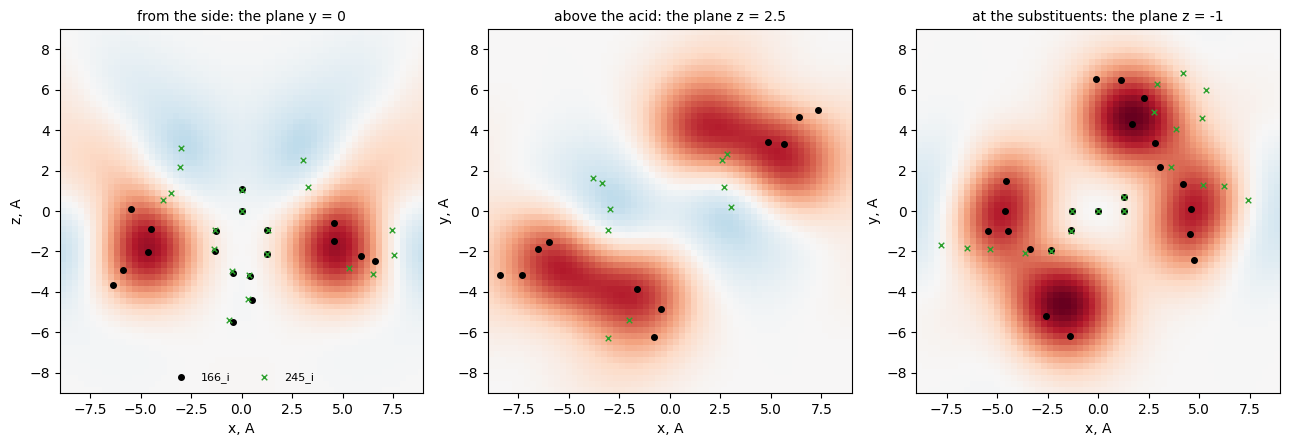

in the plane y = 0: the largest value +0.0026 is at x = +4.8, z = -1.8; the lowest value -0.0008 is at x = +2.7, z = +3.3


In [11]:
from cmfqsar.cofields import cofield_at_points

fieldset, table = field_table(FIVE, alpha)
model = CMFModel(fieldset=fieldset, method="krr")
model.params["lam"] = ridge
model.fit(table, y, cv_folds=0)
steric = fieldset.names.index("steric")

most, least = names[int(np.argmax(y))], "245_i"
u = np.linspace(-9.0, 9.0, 61)
A, B = np.meshgrid(u, u)
planes = (("from the side: the plane y = 0", "x", "z", lambda a, b: np.column_stack([a, np.zeros_like(a), b]), 1, 0.0),
          ("above the acid: the plane z = 2.5", "x", "y", lambda a, b: np.column_stack([a, b, np.full_like(a, 2.5)]), 2, 2.5),
          ("at the substituents: the plane z = -1", "x", "y", lambda a, b: np.column_stack([a, b, np.full_like(a, -1.0)]), 2, -1.0))
maps = [cofield_at_points(model, steric, points(A.ravel(), B.ravel())).reshape(A.shape) for _, _, _, points, _, _ in planes]
limit = max(np.abs(v).max() for v in maps)

fig, axes = plt.subplots(1, 3, figsize=(13.0, 4.4))
for ax, v, (title, h, w, _, normal, level) in zip(axes, maps, planes):
    ax.imshow(v, extent=[u[0], u[-1], u[0], u[-1]], origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit)
    for name, marker, colour in ((most, "o", "k"), (least, "x", "tab:green")):
        xyz = heavy_xyz[names.index(name)]
        near = np.abs(xyz[:, normal] - level) < 1.2
        ax.scatter(xyz[near, 0], xyz[near, 3 - normal], s=16, marker=marker, color=colour, lw=1, label=name)
    ax.set_xlabel(h + ", A"); ax.set_ylabel(w + ", A"); ax.set_title(title, fontsize=10)
axes[0].legend(frameon=False, fontsize=8, loc="lower center", ncol=2)
plt.tight_layout(); plt.show()

side = maps[0]
print("in the plane y = 0: the largest value %+.4f is at x = %+.1f, z = %+.1f; the lowest value %+.4f is at x = %+.1f, z = %+.1f"
      % (side.max(), A.ravel()[side.argmax()], B.ravel()[side.argmax()], side.min(), A.ravel()[side.argmin()], B.ravel()[side.argmin()]))

The map has two parts.

- **Positive lobes at the sides of the acid**, about 5 Å from the phosphorus along x and a little
  below it. This is where the first atoms of the two substituents lie. Bulk there raises the
  selectivity. The most selective catalysts, with a 2,4,6-tricyclohexylphenyl or a
  2,4,6-triisopropylphenyl group, have wide groups in this region.
- **A weaker negative region above the phosphorus**, over the pocket. Bulk that reaches over the
  pocket lowers the selectivity. The triphenylsilyl group of `245_i` puts phenyl rings there.

This is a map that a chemist can design against. A descriptor that counts how much of the space
around the catalyst is filled cannot give it, because it has no sign: it does not say where more
bulk is wanted and where less.

One limit of the map has to be said. All 43 catalysts are the same mirror image, as they were in
the screen, but the source does not say which one it is. The map is therefore correct for the
series and its mirror image is correct for the other enantiomer of the catalysts.

## From the catalyst to a single reaction

The model predicts the mean of a catalyst. A single reaction needs the shift of its pair of
substrates as well, and the table at the top showed that one offset for every pair holds most of
it. So the prediction of a reaction of a catalyst that the model has not seen is the predicted
mean of the catalyst plus the offset of the pair, taken from the other 42 catalysts.

In [12]:
predicted = np.empty_like(ddG)
reference = np.empty_like(ddG)
for i in range(len(names)):
    others = np.delete(np.arange(len(names)), i)
    offsets = ddG[others].mean(axis=0) - ddG[others].mean()
    predicted[i] = predictions["five fields"][i] + offsets
    reference[i] = ddG[others].mean(axis=0)              # the mean of the pair over the other catalysts
print("1075 reactions, each catalyst predicted without itself")
print("  field model of the catalyst plus the offset of the pair: mean absolute error %.3f kcal/mol, q2 %.2f"
      % (np.mean(np.abs(ddG - predicted)), q2(ddG.ravel(), predicted.ravel())))
print("  the mean of the pair over the other catalysts:           mean absolute error %.3f kcal/mol, q2 %.2f"
      % (np.mean(np.abs(ddG - reference)), q2(ddG.ravel(), reference.ravel())))

1075 reactions, each catalyst predicted without itself
  field model of the catalyst plus the offset of the pair: mean absolute error 0.242 kcal/mol, q2 0.80
  the mean of the pair over the other catalysts:           mean absolute error 0.458 kcal/mol, q2 0.17


The error of a single reaction is about half of what the mean of the pair gives. The paper
reports a mean absolute error of 0.211 kcal/mol for catalysts outside its training set. The two
numbers are not from the same split: the paper trained on 24 catalysts and predicted 19, and here
42 are used to predict one. They say that the simple model of this notebook is in the same range.
The manual treats the 25 pairs of substrates as 25 endpoints of one model, which reaches 0.224.

What this construction cannot do is predict a thiol or an imine that was not in the screen. The
offset of a pair is a measured number, and a new substrate has none. That needs a field of the
substrate itself, which the manual names as the next step.

## What to take from this notebook

- A selectivity is a difference of two free energies, so a series of catalysts is modelled like
  a series of ligands, if the catalysts share a frame and the reaction has one mechanism.
- The frame was given by the reaction centre, and what it adds was measured: 0.88 with it and
  about 0.75 without it, when the kernel without a frame is given a search of its own setting.
- The selectivity is steric here, and it is not the size. No count of atoms predicts it; what
  counts is where the bulk is. The co-field shows where it helps and where it hurts.
- Check the bond lengths of the structures before the model. A score does not show a faulty
  structure, and a comparison between two descriptions can depend on one.
- Give a reference the same search as the model that it is compared with.
- With 43 samples the intervals are wide. Every difference above is given with its interval for
  that reason.

The measurement of the whole table, with the 25 pairs of substrates as endpoints of one model, is
`python benchmarks/run_denmark.py`.

Where to read further in the manual: *A kinetic selectivity as the activity: a catalyst series
in the frame of its reaction centre* has the full measurement and its comparison with the
published model, the section on two endpoints explains the model with several endpoints, and
*Three tests to run before you build a new field or a new score* says how to judge a new
description before it is built.